# w2 · LSTM vs GRU per billing cycle (as_of = expiry − 7), manual segment

Two recurrent models, an **LSTM** and a **GRU**, predict churn from **90-day** tensors (14 channels) whose window ends **7 days before each customer's own expiry**, built in `w2_cycle_preprocessing.ipynb`. The customers are the manual segment (last transaction at the reference date is a payment without auto-renew) whose expiry falls in the label month.

This is the per-cycle strategy of `eda/10_per_cycle_prediction.ipynb` and `eda/07_trajectories.ipynb` (section 7), applied to w2. The run is the same as `w2_neural_models_manual.ipynb` (calendar cutoff) in every other respect: same 14 channels, same models, same Optuna budget, same split rule and threshold rule. Section 7 compares the two on the same March customers.

The primary KPI is **log-loss**, because it measures the quality of the predicted probabilities. The evaluation is temporal:

| Part | Cohort | Use |
|---|---|---|
| `fit` | February | training |
| `stop` | February | validation and early stopping |
| `tune` | February | Optuna selection and threshold |
| `test` | March | final evaluation, once |
| `development` | All February | final refit |

Both models go through exactly the same pipeline: same split, same base seed, same Optuna budget (`N_TRIALS`), same search space and the same threshold rule. Only the recurrent cell changes. The notebook only orchestrates the pieces that live in `src/models/recurrent_models/` and `src/models/evaluation/`.

## 1. Configuration

The model settings, paths and Optuna budget live in `src/models/recurrent_models/config.py`. Here they are imported and displayed so it is explicit what the run uses.

- `N_TRIALS=10`: ten candidate configurations **per model**, the same budget as the trajectory models.
- `EPOCHS=40`: maximum epochs per trial.
- `PATIENCE=5`: early stopping when `stop` does not improve for five epochs.
- `BATCH_SIZE=512`: block/batch size.
- `layer_dim` is searched between 2 and 4; `hidden_dim` among 32, 64 and 128.
- `lr` and `weight_decay` are searched on a logarithmic scale.

Each model writes to its own folder, `artifacts/sherlock_w2_v6_manual_cycle_k7/<model>/` (`optuna/`, `checkpoints/`, `evaluation/`). The side-by-side outputs go to `artifacts/sherlock_w2_v6_manual_cycle_k7/comparison/`.

In [1]:
import torch; torch.cuda.is_available()

True

In [2]:
from pathlib import Path
import os

# Run selection, read by src.models at import time: per-cycle export, k = 7, manual segment.
os.environ["W2_ALIGNMENT"] = "cycle"
os.environ["W2_CYCLE_K"] = "7"
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

warnings.filterwarnings("ignore")

# src.models reads the run selection once, at import time: a kernel that imported
# older code or another selection must be restarted.
import sys
_loaded = sys.modules.get("src.models.constants")
if _loaded is not None and (getattr(_loaded, "DATASET_VERSION", None) != 6
                            or _loaded.ALIGNMENT != os.environ.get("W2_ALIGNMENT", "calendar")):
    raise RuntimeError("This kernel holds an old src.models (or another run selection). "
                       "Restart the kernel and run the notebook from the top.")

from src.models.recurrent_models.config import (
    BATCH_SIZE,
    EPOCHS,
    EXPORT_DIR,
    FEATURE_DIR,
    HIDDEN_DIMS,
    INPUT_DIM,
    LAYER_DIM_RANGE,
    LR_RANGE,
    N_TRIALS,
    OUTPUT_DIM,
    PATIENCE,
    SEED,
    WEIGHT_DECAY_RANGE,
    model_dirs,
)
from src.models.recurrent_models.recurrent_classifier import GRUModel, LSTMModel
from src.models.recurrent_models.train import resolve_device
from src.models.evaluation.compare import COMPARISON_DIR

DEVICE = resolve_device()

# model_name -> model class. Every loop below iterates over this dict.
MODELS = {"lstm": LSTMModel, "gru": GRUModel}

settings = pd.DataFrame(
    [
        ("models", ", ".join(name.upper() for name in MODELS)),
        ("export_dir", str(EXPORT_DIR)),
        ("feature_dir", str(FEATURE_DIR)),
        ("comparison_dir", str(COMPARISON_DIR)),
        ("device", str(DEVICE)),
        ("seed", SEED),
        ("n_trials", N_TRIALS),
        ("epochs", EPOCHS),
        ("patience", PATIENCE),
        ("batch_size", BATCH_SIZE),
        ("input_dim", INPUT_DIM),
        ("output_dim", OUTPUT_DIM),
        ("hidden_dims", HIDDEN_DIMS),
        ("layer_dim_range", LAYER_DIM_RANGE),
        ("lr_range", LR_RANGE),
        ("weight_decay_range", WEIGHT_DECAY_RANGE),
    ],
    columns=["setting", "value"],
)
display(settings)

# Artifact folders per model.
pd.DataFrame({name.upper(): {k: str(v) for k, v in model_dirs(name).items()} for name in MODELS})

,setting,value
0,models,"LSTM, GRU"
1,export_dir,export-sequential-v6-cycle-k7-manual
2,feature_dir,artifacts/sherlock_w2_v6_manual_cycle_k7/featu...
3,comparison_dir,artifacts/sherlock_w2_v6_manual_cycle_k7/compa...
4,device,cuda
5,seed,110
6,n_trials,10
7,epochs,40
8,patience,5
9,batch_size,512


,LSTM,GRU
artifacts,artifacts/sherlock_w2_v6_manual_cycle_k7/lstm,artifacts/sherlock_w2_v6_manual_cycle_k7/gru
optuna,artifacts/sherlock_w2_v6_manual_cycle_k7/lstm/...,artifacts/sherlock_w2_v6_manual_cycle_k7/gru/o...
checkpoints,artifacts/sherlock_w2_v6_manual_cycle_k7/lstm/...,artifacts/sherlock_w2_v6_manual_cycle_k7/gru/c...
evaluation,artifacts/sherlock_w2_v6_manual_cycle_k7/lstm/...,artifacts/sherlock_w2_v6_manual_cycle_k7/gru/e...


## 2. Feature preparation

### 2.1 Data

`export-sequential-v6-cycle-k7-manual` contains a `(users, 90, 14)` `float16` tensor per cohort, with days ordered from oldest to newest; the last day is each customer's `as_of` = expiry − 7. The channels are:

- `0:8`: listening. Seven counters transformed with `log1p` plus the `active` flag.
- `8:11`: daily payment events (`tx_count`, `tx_paid_sum`, `tx_plan_days_sum`), zero on days without a payment.
- `11:14`: payment state carried forward (`tx_state_known`, `tx_days_since_last`, `tx_days_to_expire`).

The `is_churn` labels are aligned row by row with the tensor. Every channel uses only records dated on or before each customer's `as_of`, so there is no temporal leakage: the label depends on what happens from the expiry onwards.

The export is small (about 400 MB per cohort), so `load_prepared_data` loads it into RAM once and scales it once per phase (about 25 s each); every epoch then slices in-memory arrays. Exports above `W2_RAM_CACHE_GB` (default 8, e.g. the whole cohort) are read from the memory map block by block instead.

The cell below runs the feature preparation for this export (split, scalers fitted on `fit` and on all of February). The export is already restricted to the manual segment, so no rows are filtered here.

**Channels: 14.** The export holds exactly the channels the networks read: the 8 listening channels, 3 payment events and 3 payment states. The other six channels computed by the builder (cancel / auto-renew counters and flags, `tx_expiry_known`, `tx_state_ambiguous`) are almost constant in the manual segment and are not exported (`w2_sequence_preprocessing.ipynb`, section 7).

In [3]:
from src.models.feature_preparation.prepare import prepare

prepared = prepare()   # reads EXPORT_DIR, writes FEATURE_DIR (both shown in the configuration table)

input: export-sequential-v6-cycle-k7-manual | output: artifacts/sherlock_w2_v6_manual_cycle_k7/feature_preparation | on_kaggle: False
dataset_version: 6 | cutoffs: {'train_feb': '2017-01-31', 'test': '2017-02-28'}
train_feb rows:   104,964 | label month: 2017-02 | churn rate: 0.2931
test      rows:   104,322 | label month: 2017-03 | churn rate: 0.3831
labelled cohorts: (209286, 4) | users in both months: 52947
stacked sequence view: (209286, 90, 14) float16
saved split_indices.npz and split_summary.csv | fit churn rate: 0.29309
part    cohort label_month  n_users  share_of_cohort  churn_rate  n_churn  n_stay
 fit train_feb     2017-02    78723         0.750000     0.29309    23073   55650
stop train_feb     2017-02    13121         0.125005     0.29312     3846    9275
tune train_feb     2017-02    13120         0.124995     0.29306     3845    9275
test      test     2017-03   104322         1.000000     0.38313    39969   64353
fitted phase 'fit': rows=78,723 | file=preprocessing/fit

In [4]:
from src.models.recurrent_models.data import load_prepared_data

data = load_prepared_data(feature_dir=FEATURE_DIR, export_dir=EXPORT_DIR)

print("tensor:", data.view.shape, data.view.dtype)
print("input_dim:", data.input_dim)
print("channels:", data.meta["sequences"]["lstm"]["channels"])
print("split sizes:", {part: len(rows) for part, rows in data.split.items()})
for part in ("fit", "stop", "tune", "test"):
    labels = data.labels(part)
    print(f"{part:4s} n={len(labels):>9,} | churn_rate={labels.mean():.4f}")

train_feb rows:   104,964 | label month: 2017-02 | churn rate: 0.2931
test      rows:   104,322 | label month: 2017-03 | churn rate: 0.3831
labelled cohorts: (209286, 4) | users in both months: 52947
sequence data: 209,286 rows | RAM cache on (needs 1.1 GB, limit 8 GB)
tensor: (209286, 90, 14) float16
input_dim: 14
channels: ['num_25', 'num_50', 'num_75', 'num_985', 'num_100', 'num_unq', 'total_secs', 'active', 'tx_count', 'tx_paid_sum', 'tx_plan_days_sum', 'tx_state_known', 'tx_days_since_last', 'tx_days_to_expire']
split sizes: {'fit': 78723, 'stop': 13121, 'tune': 13120, 'test': 104322, 'development': 104964}
fit  n=   78,723 | churn_rate=0.2931
stop n=   13,121 | churn_rate=0.2931
tune n=   13,120 | churn_rate=0.2931
test n=  104,322 | churn_rate=0.3831


### 2.2 Split

February is split once with a stable `msno` hash, stratified by label:

- `fit`: 75%.
- `stop`: 12.5%.
- `tune`: 12.5%.
- `test`: every eligible March customer of the segment, never used for any decision.
- `development`: all eligible February customers of the segment; used only for the final refit before predicting March.

This keeps the threshold honest: it is selected on `tune` and never re-searched on `test`.

In [5]:
split_table = pd.DataFrame(
    [
        {
            "part": part,
            "n_users": len(data.split[part]),
            "churn_rate": float(data.labels(part).mean()),
        }
        for part in ("fit", "stop", "tune", "test", "development")
    ]
)
split_table

,part,n_users,churn_rate
0,fit,78723,0.293091
1,stop,13121,0.293118
2,tune,13120,0.293064
3,test,104322,0.383131
4,development,104964,0.293091


### 2.3 Prepared dataset and batches

The existing `PreparedSequenceData` class encapsulates:

- the labels,
- the split indices,
- the tensor, held in RAM (raw once, scaled once per phase),
- the scalers fitted per phase.

Its `iter_batches` method returns batches of scaled rows as PyTorch tensors, sliced from the in-memory scaled tensor of the requested phase, so the scaler is applied once per phase instead of once per batch and epoch.

- `phase="fit"`: scaler fitted only on `fit`.
- `phase="development"`: scaler fitted on all of February.
- `drop_last=True`: avoids a final batch of size 1, which `BatchNorm1d` cannot normalise during training.

In [6]:
sample_rows = data.rows("fit")[:BATCH_SIZE]
xb, yb = next(
    iter(data.iter_batches(sample_rows, "fit", BATCH_SIZE, drop_last=True))
)
print("x:", xb.shape, xb.dtype)
print("y:", yb.shape, yb.dtype)
print("first user, channel 0, day 0:", float(xb[0, 0, 0]))

loaded raw tensor into RAM: (209286, 90, 14) float16 in 0.3s
scaled tensor for phase 'fit' cached in 5.0s
x: torch.Size([512, 90, 14]) torch.float32
y: torch.Size([512, 1]) torch.float32
first user, channel 0, day 0: 0.0


## 3. Model and training

### 3.1 Architecture: LSTM and GRU

The input is `(batch, 90, 14)`: the 14 channels of the export. Both networks stack between **2 and 4 recurrent layers** and share the same head; only the recurrent cell changes (`RecurrentClassifier` with `rnn_cls = nn.LSTM` or `nn.GRU`).

- **LSTM**: input, forget and output gates plus a cell state `c_t`. Four weight blocks per layer.
- **GRU**: update and reset gates, no separate cell state. Three weight blocks per layer, so about **25% fewer parameters** for the same `hidden_dim` and usually faster epochs.

In both cases the last hidden output `h_T` summarises the 90-day history. After `h_T`:

1. `BatchNorm1d(hidden_dim)` stabilises the hidden-state distribution.
2. `Linear(hidden_dim, 1)` produces a logit.
3. At prediction time, `Sigmoid` turns the logit into a churn probability.

`forward` returns only the logit, so both families expose the same interface. There is no dropout, as specified. Overfitting is controlled by `weight_decay`, BatchNorm and early stopping.

The loss is `BCEWithLogitsLoss`: the numerically stable version of binary cross-entropy that works directly with logits.

In [7]:
# Same configuration for both cells: same output shape, different parameter count.
for name, model_cls in MODELS.items():
    example = model_cls(
        input_dim=INPUT_DIM, hidden_dim=64, layer_dim=2, output_dim=OUTPUT_DIM
    ).to(DEVICE).eval()
    with torch.no_grad():
        logits = example(xb.to(DEVICE))
    n_params = sum(p.numel() for p in example.parameters())
    print(
        f"{name.upper():4s} | logits {tuple(logits.shape)} | parameters {n_params:,}"
        f" | example probabilities {torch.sigmoid(logits[:3]).cpu().numpy().ravel().round(3)}"
    )

LSTM | logits (512, 1) | parameters 53,953 | example probabilities [0.463 0.465 0.463]
GRU  | logits (512, 1) | parameters 40,513 | example probabilities [0.481 0.468 0.477]


### 3.2 Optimisation

- **AdamW** decouples weight decay from the adaptive step.
- `lr` and `weight_decay` are searched with Optuna.
- **Gradient clipping** at norm 1.0 for recurrent-network stability.
- **AMP** on GPU for speed.
- At most **40 epochs** per trial.
- **Early stopping** with `patience=5`: if `stop` does not improve, training stops and the best checkpoint is restored.
- No dropout.

### 3.3 Optuna

Optuna uses TPE and minimises `log_loss` on `tune`:

- trains on `fit`,
- validates on `stop`,
- evaluates on `tune`,
- restores the best `stop` state before computing the objective.

The search space is the same for both models:

- `layer_dim`: 2–4.
- `hidden_dim`: 32, 64, 128.
- `lr`: `1e-4` to `1e-2` on a logarithmic scale.
- `weight_decay`: `1e-6` to `1e-2` on a logarithmic scale.
- `batch_size`: fixed at 512.

Each study is written under `artifacts/sherlock_w2_v6_manual_cycle_k7/<model>/optuna/`: the SQLite study, the trials CSV, the best-parameters JSON and the per-epoch history of the best trial.

In [8]:
from src.models.recurrent_models.tune import tune_model

best = {}
for name, model_cls in MODELS.items():
    print(f"\n===== {name.upper()} =====")
    best[name] = tune_model(
        data,
        model_name=name,
        recurrent_model_class=model_cls,
        n_trials=N_TRIALS,
        epochs=EPOCHS,
        patience=PATIENCE,
        batch_size=BATCH_SIZE,
        device=DEVICE,
        seed=SEED,
        verbose=True,
    )

pd.DataFrame(
    {
        name.upper(): {
            "tune log-loss": result["best_value"],
            "threshold": result["threshold"],
            "best epoch": result["best_epoch"],
            "stopped epoch": result["stopped_epoch"],
            "trial": result["trial_number"],
            **result["best_params"],
        }
        for name, result in best.items()
    }
)


===== LSTM =====
Optuna budget=10 | remaining=0
best trial #0: loss=0.51071 | threshold=0.28 | best_epoch=14 | params={'layer_dim': 2, 'hidden_dim': 32, 'lr': 0.002285499365417053, 'weight_decay': 0.0005368494554109796, 'batch_size': 512}

===== GRU =====
Optuna budget=10 | remaining=3


  0%|          | 0/3 [00:00<?, ?it/s]

trial 7: starting | params={'layer_dim': 4, 'hidden_dim': 64, 'lr': 0.00012855951838753365, 'weight_decay': 0.001412895483183722, 'batch_size': 512}
trial 7 | epoch 01 | train=0.64334 | stop=0.59867
trial 7 | epoch 02 | train=0.60825 | stop=0.57230
trial 7 | epoch 03 | train=0.58542 | stop=0.54303
trial 7 | epoch 04 | train=0.55646 | stop=0.54459
trial 7 | epoch 05 | train=0.54221 | stop=0.52413
trial 7 | epoch 06 | train=0.53255 | stop=0.52267
trial 7 | epoch 07 | train=0.52775 | stop=0.51818
trial 7 | epoch 08 | train=0.52480 | stop=0.52247
trial 7 | epoch 09 | train=0.52274 | stop=0.52580
trial 7 | epoch 10 | train=0.52082 | stop=0.51643
trial 7 | epoch 11 | train=0.52063 | stop=0.52124
trial 7 | epoch 12 | train=0.51943 | stop=0.51926
trial 7 | epoch 13 | train=0.51934 | stop=0.51657
trial 7 | epoch 14 | train=0.51867 | stop=0.53248
trial 7 | epoch 15 | train=0.51887 | stop=0.51470
trial 7 | epoch 16 | train=0.51888 | stop=0.51944
trial 7 | epoch 17 | train=0.51846 | stop=0.52360
t

,LSTM,GRU
tune log-loss,0.510710,0.509046
threshold,0.280000,0.330000
best epoch,14.000000,10.000000
stopped epoch,19.000000,15.000000
trial,0.000000,4.000000
layer_dim,2.000000,2.000000
hidden_dim,32.000000,32.000000
lr,0.002285,0.006184
weight_decay,0.000537,0.000017
batch_size,512.000000,512.000000


### 3.4 Training history

`train_loss` vs `stop_loss` per epoch for the best trial of each study. One panel per model, with the same y-axis (`sharey=True`) so the levels can be compared without overlaying four curves. The dotted line marks the `best_epoch` restored by early stopping.

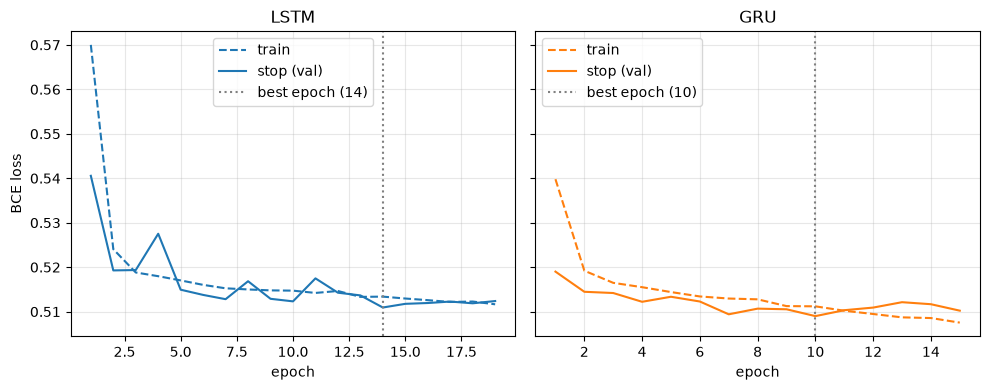

In [9]:
from src.models.evaluation.optuna_history import plot_training_history

COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
history_fig = plot_training_history(
    tuple(MODELS), save_path=COMPARISON_DIR / "training_history.png"
)
plt.show()

## 4. Test

For each model, the threshold was already selected on `tune` and is now frozen. The final refit uses all of February (`development`) for the `best_epoch` found during tuning. March is then predicted once.

A checkpoint with the architecture, parameters, threshold and epoch count is saved to `artifacts/sherlock_w2_v6_manual_cycle_k7/<model>/checkpoints/<model>.pt`. The refit time is also recorded, so the comparison can report time per epoch.

In [10]:
from src.models.recurrent_models.test import test_model


def make_builder(model_cls):
    """Build ``model_cls`` from the tuned hyper-parameters."""
    def build(best_params, input_dim):
        return model_cls(
            input_dim=input_dim,
            hidden_dim=int(best_params["hidden_dim"]),
            layer_dim=int(best_params["layer_dim"]),
            output_dim=OUTPUT_DIM,
        )
    return build


results = {}
for name, model_cls in MODELS.items():
    print(f"\n===== {name.upper()} =====")
    results[name] = test_model(
        best[name]["best_params"],
        data,
        threshold=best[name]["threshold"],
        best_epoch=best[name]["best_epoch"],
        device=DEVICE,
        seed=SEED,
        verbose=True,
        build_model=make_builder(model_cls),
        model_name=name,
    )

pd.DataFrame(
    {
        name.upper(): {
            "test users": len(result["proba_test"]),
            "predicted churn rate": result["pred_test"].mean(),
            "threshold": result["threshold"],
            "epochs": result["epochs"],
            "seconds / epoch": result["seconds_per_epoch"],
            "checkpoint": str(result["checkpoint"]),
        }
        for name, result in results.items()
    }
)


===== LSTM =====
scaled tensor for phase 'development' cached in 4.7s
final | epoch 01 | train=0.55928
final | epoch 02 | train=0.51970
final | epoch 03 | train=0.51750
final | epoch 04 | train=0.51564
final | epoch 05 | train=0.51568
final | epoch 06 | train=0.51482
final | epoch 07 | train=0.51389
final | epoch 08 | train=0.51378
final | epoch 09 | train=0.51344
final | epoch 10 | train=0.51336
final | epoch 11 | train=0.51331
final | epoch 12 | train=0.51250
final | epoch 13 | train=0.51195
final | epoch 14 | train=0.51149

===== GRU =====
final | epoch 01 | train=0.53464
final | epoch 02 | train=0.51661
final | epoch 03 | train=0.51499
final | epoch 04 | train=0.51356
final | epoch 05 | train=0.51295
final | epoch 06 | train=0.51271
final | epoch 07 | train=0.51124
final | epoch 08 | train=0.51046
final | epoch 09 | train=0.51024
final | epoch 10 | train=0.50866


,LSTM,GRU
test users,104322,104322
predicted churn rate,0.410613,0.362071
threshold,0.28,0.33
epochs,14,10
seconds / epoch,1.342062,1.017084
checkpoint,artifacts/sherlock_w2_v6_manual_cycle_k7/lstm/...,artifacts/sherlock_w2_v6_manual_cycle_k7/gru/c...


## 5. Per-model diagnostics

`evaluate_model` writes the complete evaluation of each model to `artifacts/sherlock_w2_v6_manual_cycle_k7/<model>/evaluation/`:

- `test` metrics at the `tune` threshold,
- complementary metrics at `0.5`,
- classification report,
- confusion matrix,
- reliability/histogram,
- threshold manifest,
- training history of the best trial.

These are internal diagnostics, so they are shown **one model at a time**. The direct comparison (ROC/PR, gain/lift, tables) is in section 6.

`log_loss` measures probability quality. `ROC-AUC` and `average_precision` measure ranking. `F1`, `precision` and `recall` measure decisions at the chosen threshold.

In the confusion matrix:

- **FN**: churners the model missed.
- **FP**: loyal customers flagged as at risk.

Each threshold was selected in February and is not optimised again in March.

In [11]:
from src.models.evaluation import evaluate_model

reports = {
    name: evaluate_model(
        results[name],
        best[name],
        data,
        model_name=name,
        show_plots=False,
    )
    for name in MODELS
}
pd.concat([report["display"] for report in reports.values()], ignore_index=True)

,model_id,family,input,n_channels,n_parameters,best_epoch,tune_log_loss,log_loss,roc_auc,average_precision,brier,accuracy,balanced_accuracy,precision_churn,recall_churn,specificity,f1_churn,f1_macro,mcc,threshold
0,LSTM,lstm,sequence,14,14689,14,0.51071,0.59458,0.76536,0.66606,0.20456,0.72996,0.72115,0.63771,0.68345,0.75885,0.65979,0.71796,0.43709,0.28
1,GRU,gru,sequence,14,11041,10,0.50905,0.56299,0.78516,0.70565,0.18971,0.74900,0.72929,0.68246,0.64495,0.81362,0.66318,0.73157,0.46387,0.33



===== LSTM =====
confusion_png -> artifacts/sherlock_w2_v6_manual_cycle_k7/lstm/evaluation/figures/confusion/confusion_LSTM_test.png


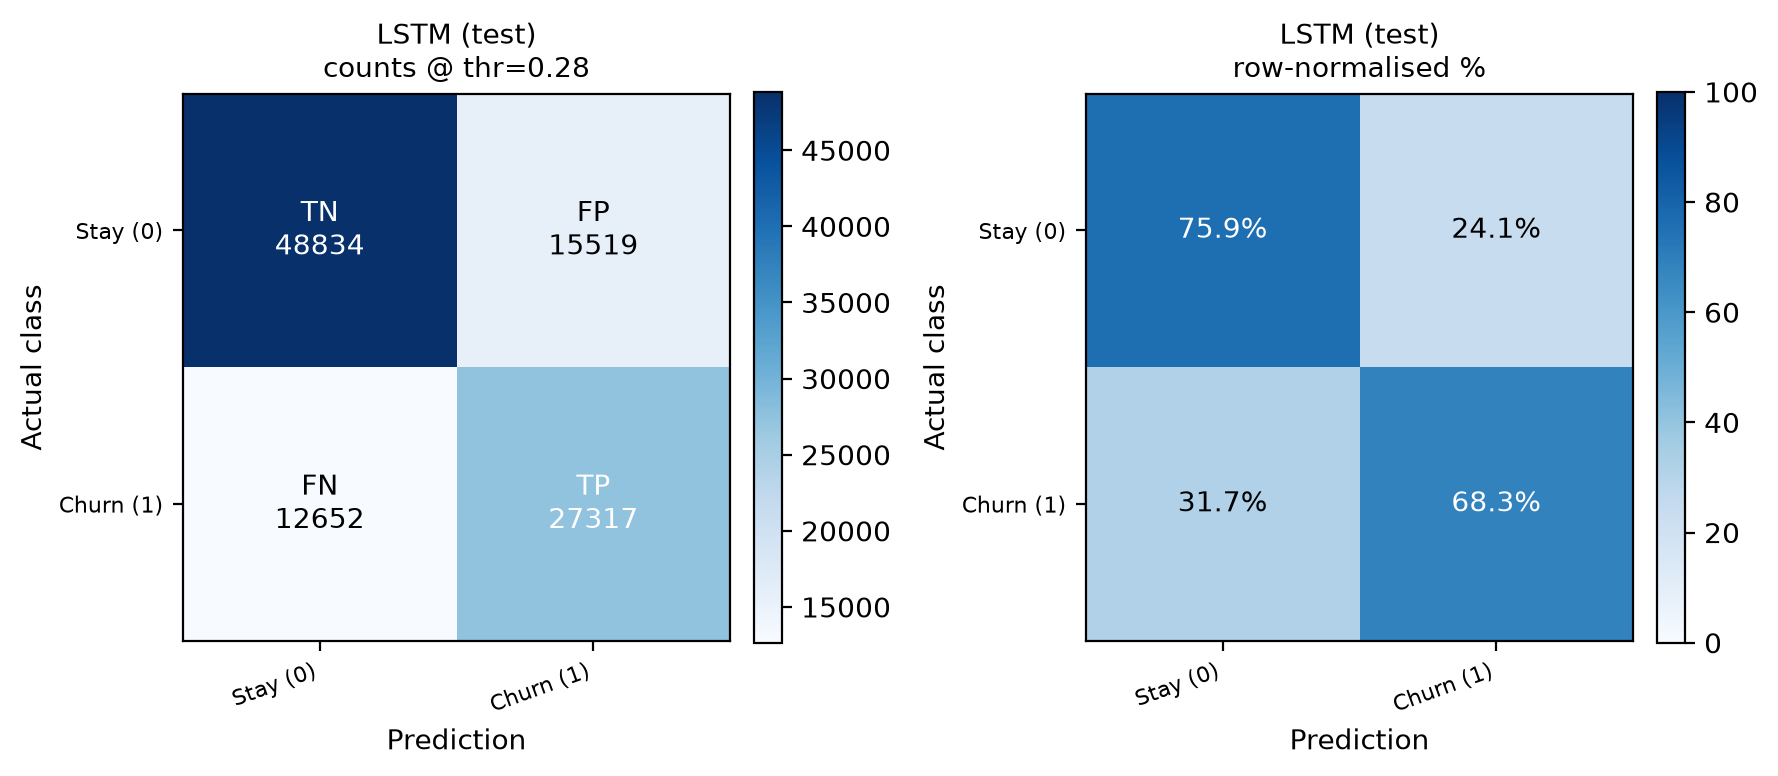

calibration -> artifacts/sherlock_w2_v6_manual_cycle_k7/lstm/evaluation/figures/curves/calibration_hist.png


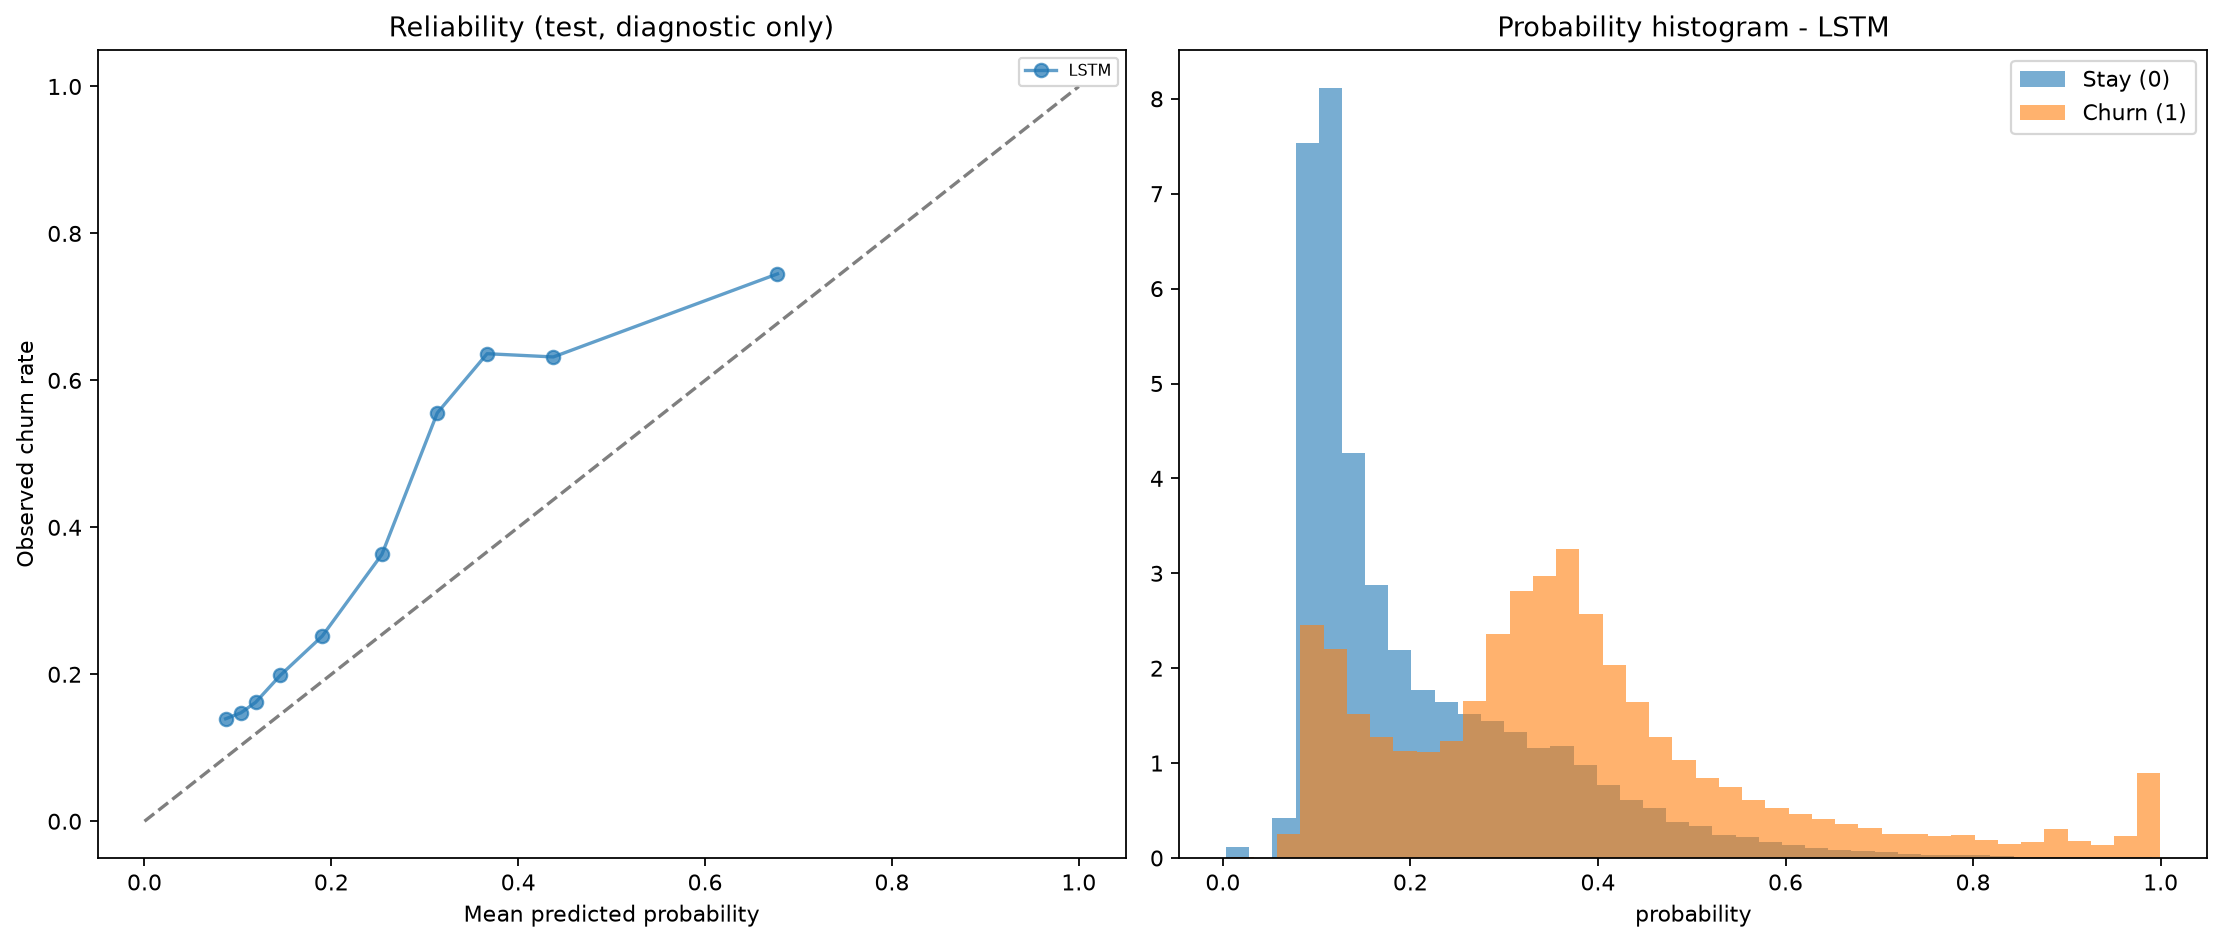

optuna_history -> artifacts/sherlock_w2_v6_manual_cycle_k7/lstm/evaluation/figures/lstm_training_history.png


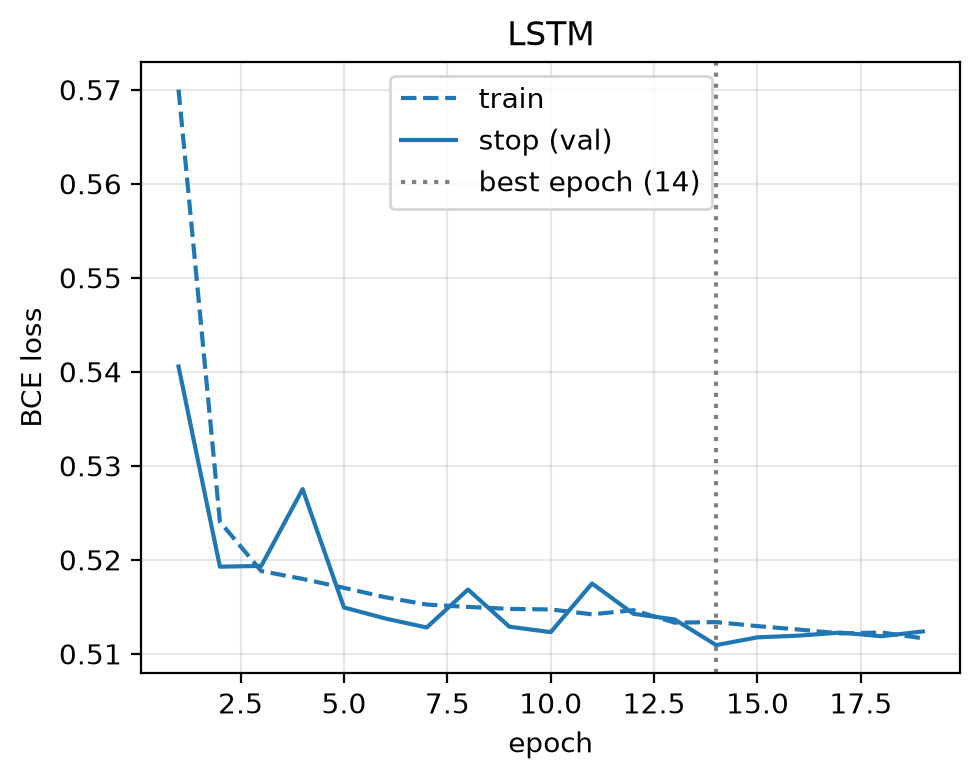


===== GRU =====
confusion_png -> artifacts/sherlock_w2_v6_manual_cycle_k7/gru/evaluation/figures/confusion/confusion_GRU_test.png


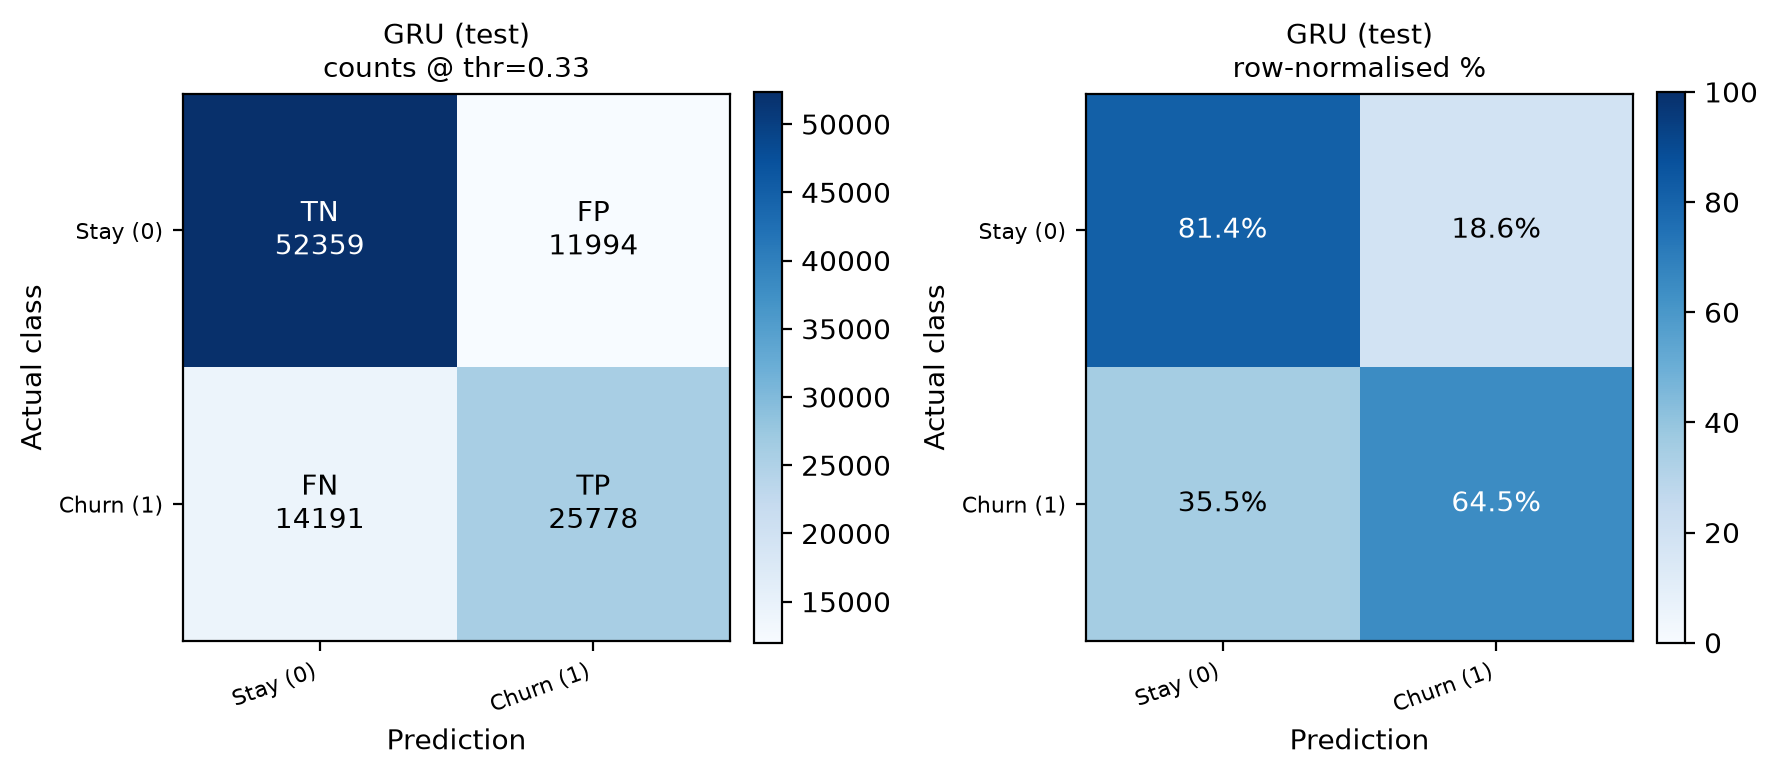

calibration -> artifacts/sherlock_w2_v6_manual_cycle_k7/gru/evaluation/figures/curves/calibration_hist.png


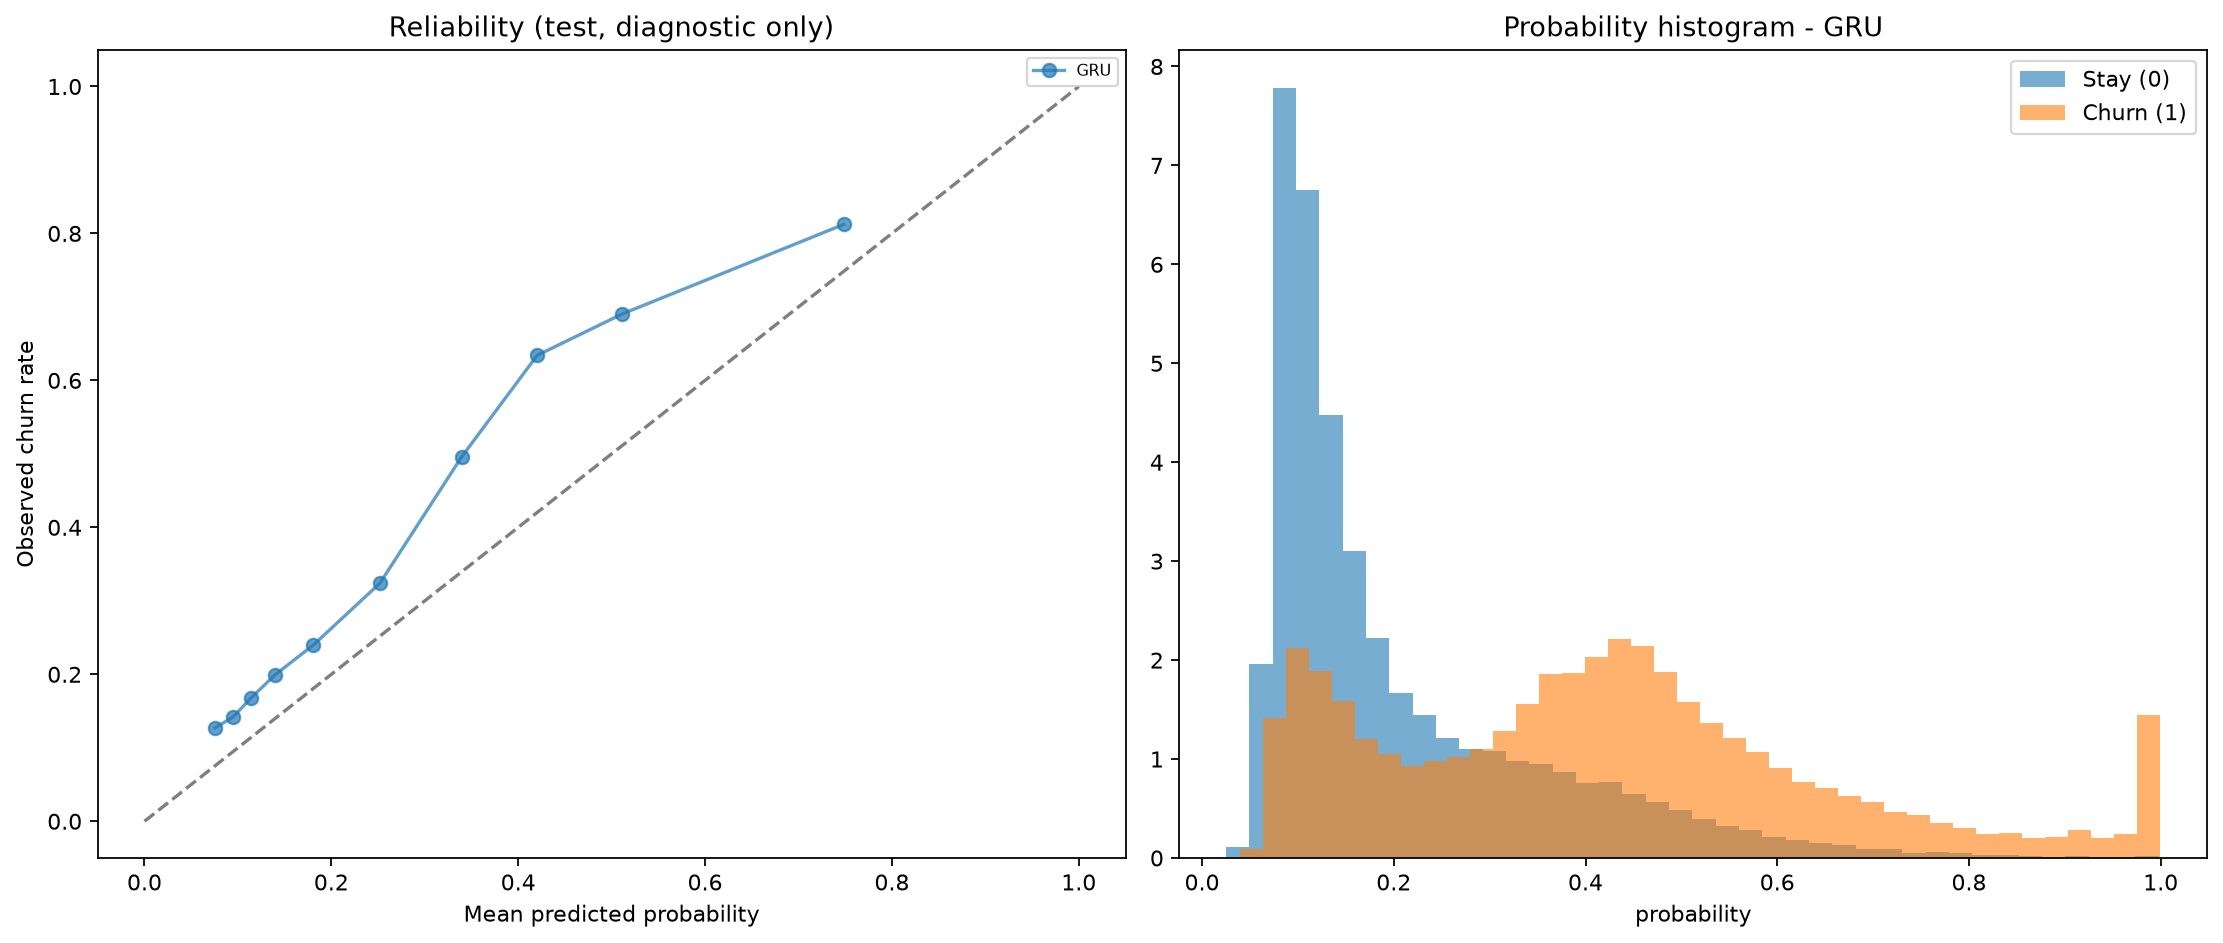

optuna_history -> artifacts/sherlock_w2_v6_manual_cycle_k7/gru/evaluation/figures/gru_training_history.png


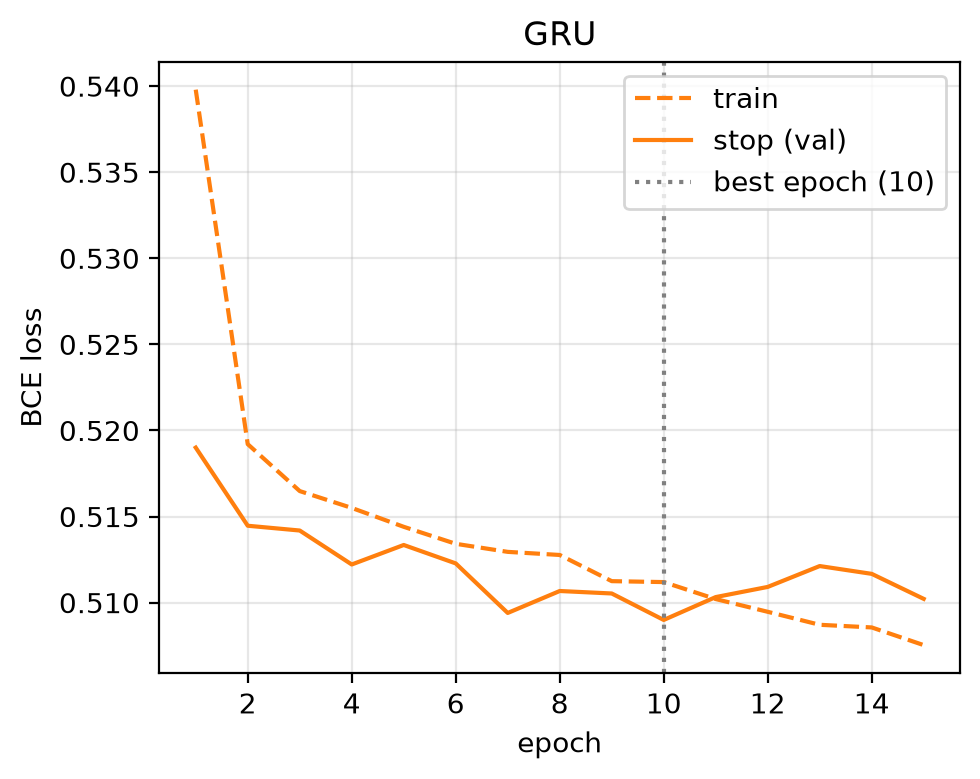

In [12]:
for name, report in reports.items():
    print(f"\n===== {name.upper()} =====")
    for key in ("confusion_png", "calibration", "optuna_history"):
        path = report["paths"].get(key)
        if path is not None and Path(path).is_file():
            print(key, "->", path)
            display(Image(filename=str(path)))

## 6. LSTM vs GRU comparison

`compare_models` puts both models on the same axes and in the same tables, with LSTM always in blue and GRU always in orange:

- **ROC and Precision-Recall**, one line per model. PR is the more informative one because churn is the minority class.
- **Cumulative gain and lift**: share of churners captured when contacting the top-risk users first, for retention campaigns.
- **Metrics table**: AUC-ROC, AUC-PR, F1, log-loss, parameters and time per epoch, with the best value of each column in bold.
- **Paired bootstrap** (1000 resamples of the test users): 95% intervals per model and for the difference LSTM − GRU. Both models are scored on the same resampled users, so the interval of the difference accounts for their correlation. A difference is significant when its interval excludes 0.
- **DeLong test** for the difference in AUC-ROC.
- **Best hyper-parameters** of each model (annex table).

Every metric uses each model's own `tune` threshold; nothing is tuned on `test`.

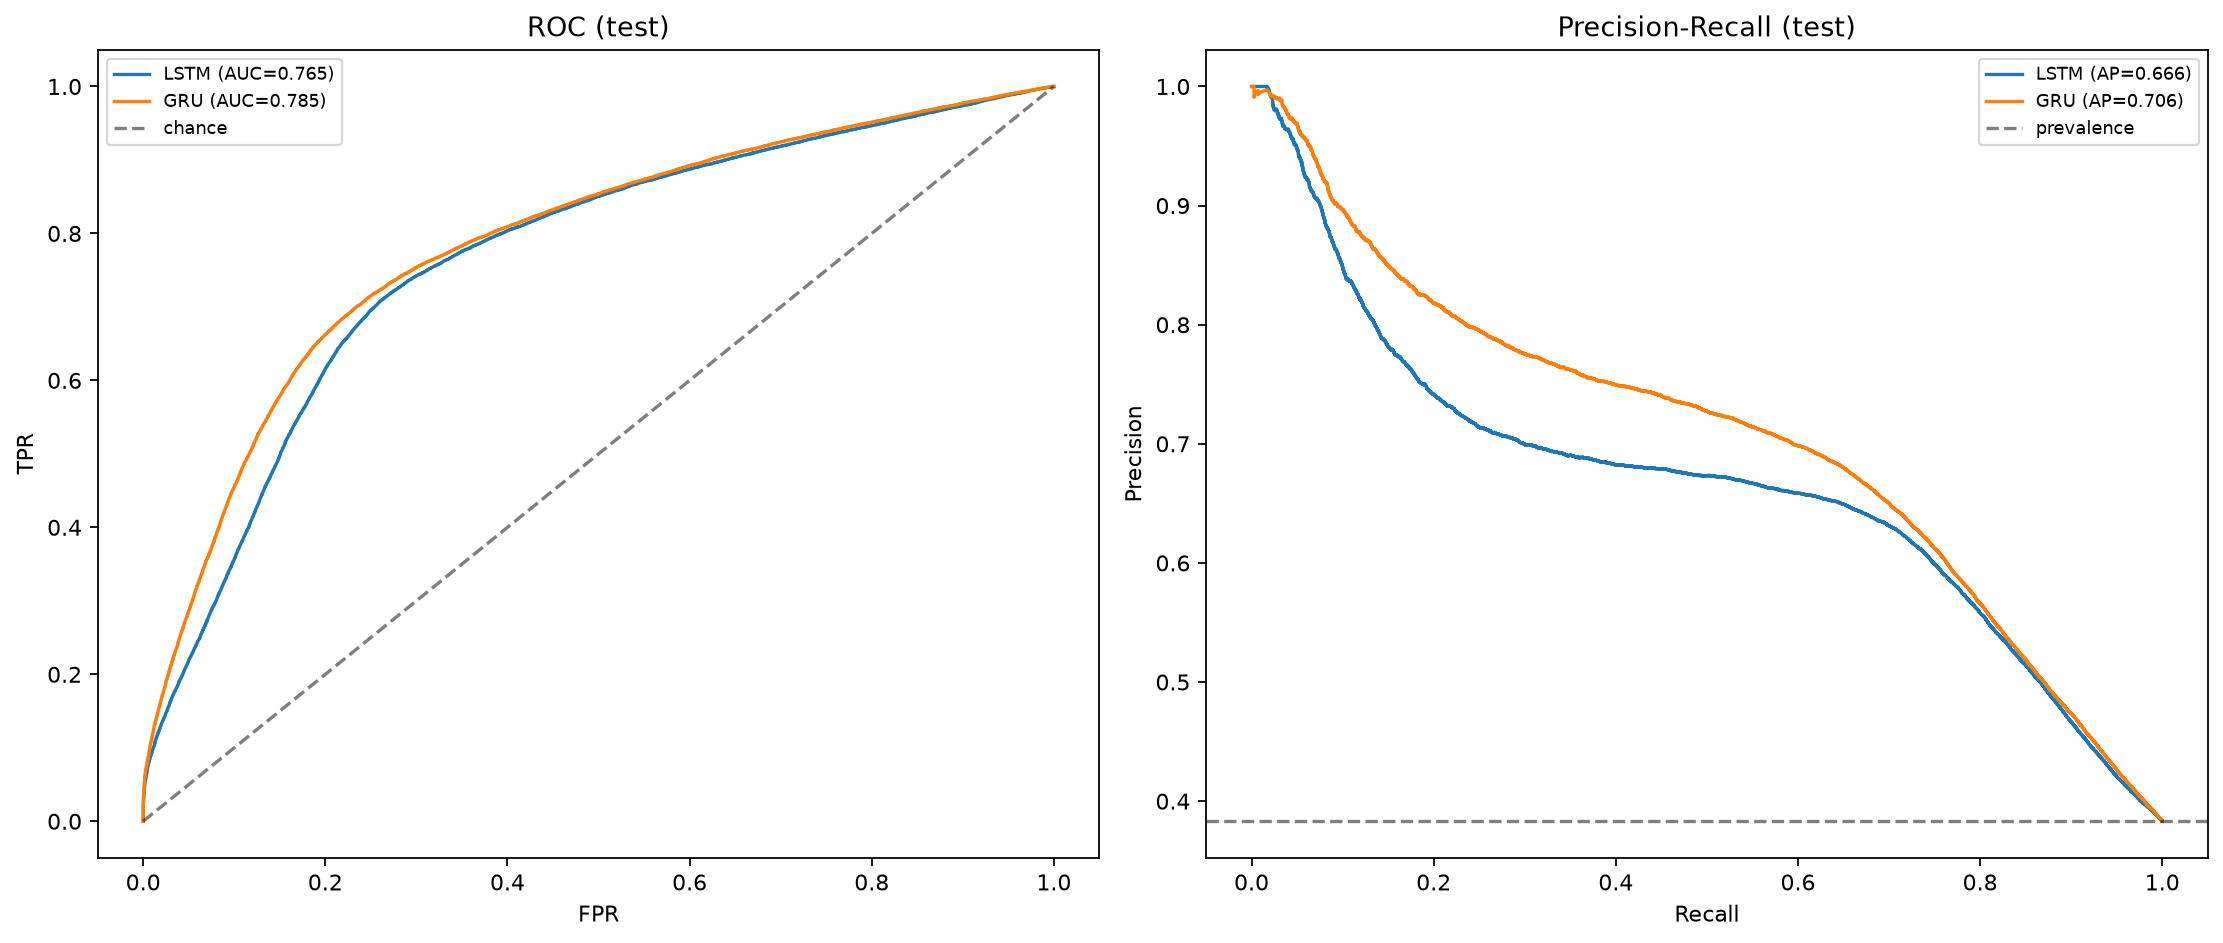

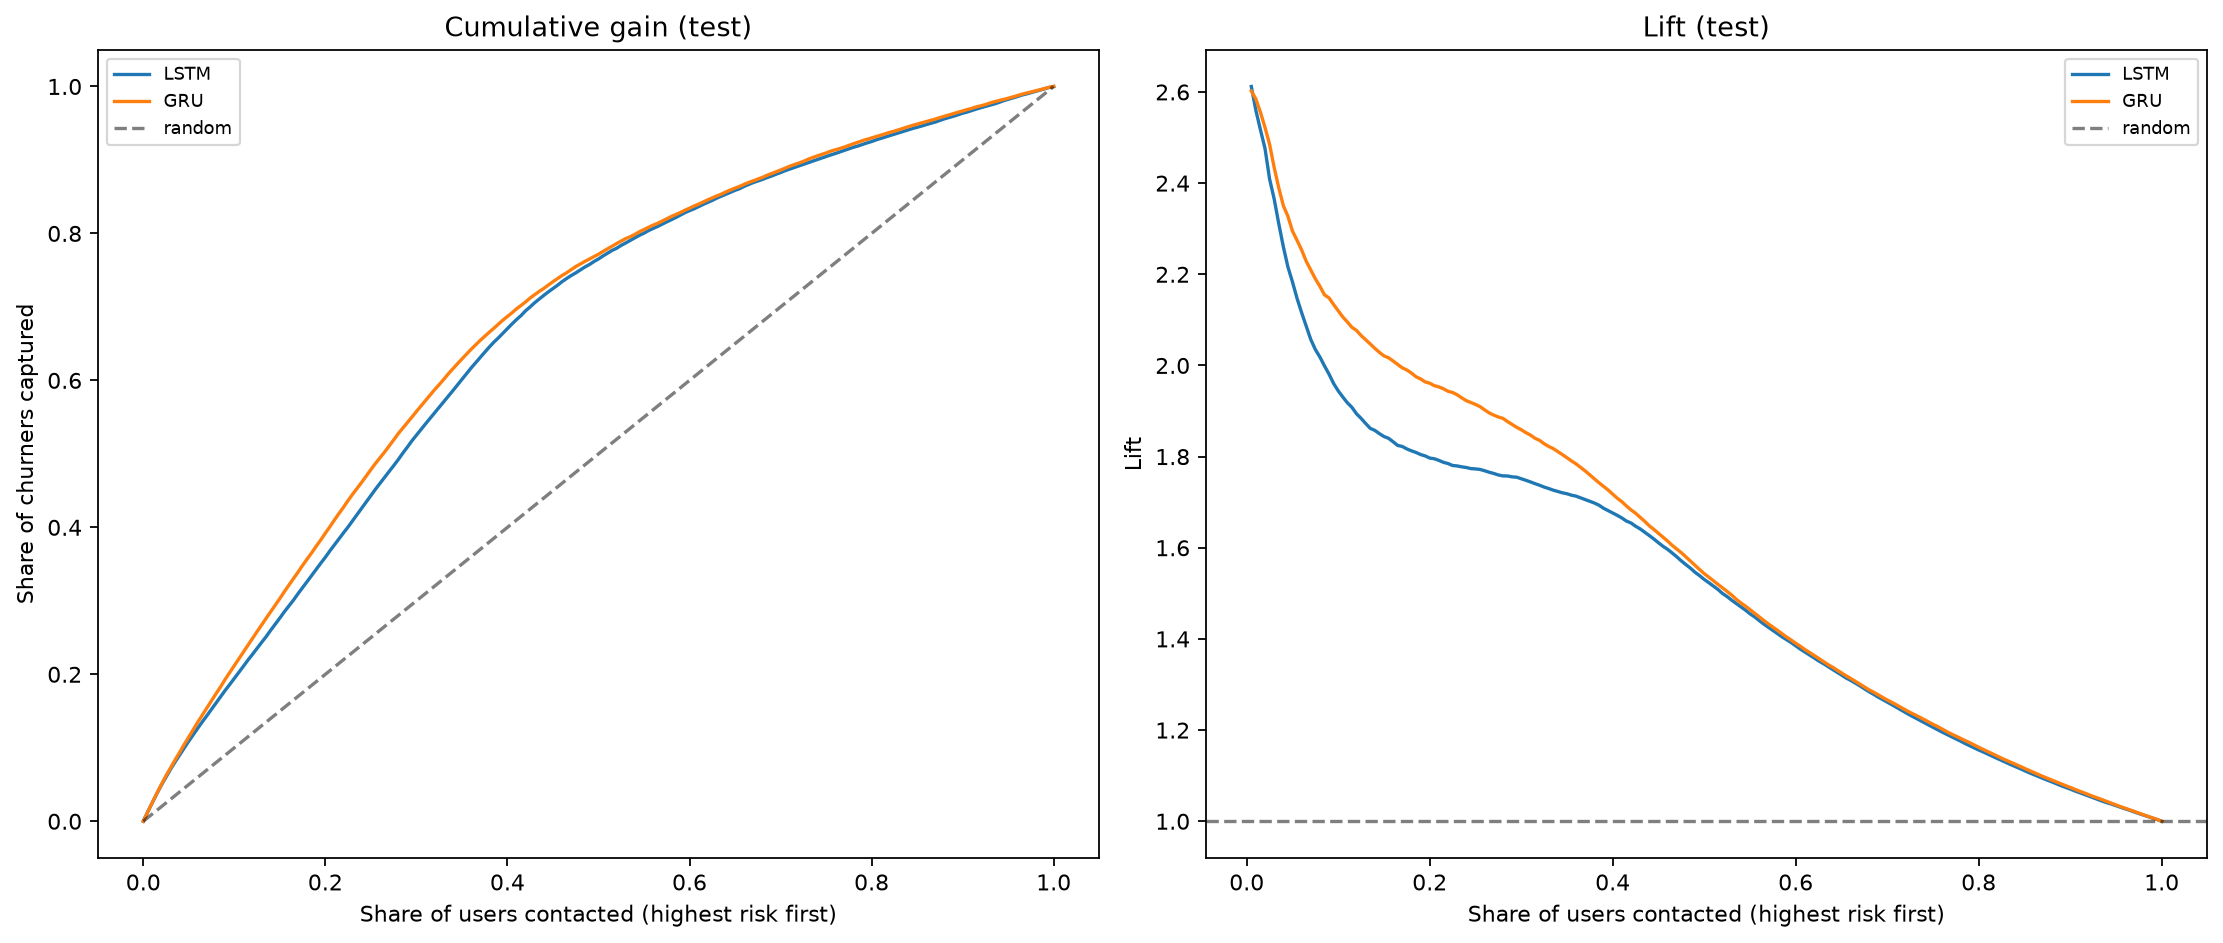

,AUC-ROC,AUC-PR,F1,Log-loss,Parámetros,Tiempo/época (s),Umbral
Modelo,,,,,,,
LSTM,0.7654,0.6661,0.6598,0.5946,"14,689",1.34,0.28
GRU,0.7852,0.7057,0.6632,0.5630,"11,041",1.02,0.33


In [13]:
from src.models.evaluation import compare_models

comparison = compare_models(runs=results, tunes=best, show_plots=False)

for key in ("roc_pr", "gain_lift"):
    display(Image(filename=str(comparison["paths"][key])))

comparison["display"]

In [14]:
print("Paired bootstrap, 95% CI (difference = LSTM - GRU)")
display(comparison["bootstrap"])

delong = comparison["delong"]
print(
    f"DeLong AUC-ROC: {delong['model_a']}={delong['auc_a']:.4f}"
    f" | {delong['model_b']}={delong['auc_b']:.4f}"
    f" | diff={delong['diff']:+.4f} | z={delong['z']:.2f} | p={delong['p_value']:.3g}"
)

print("\nGain and lift at fixed contact rates")
display(comparison["lift"].round(3))

print("Best hyper-parameters (annex)")
display(comparison["hyperparams"])

Paired bootstrap, 95% CI (difference = LSTM - GRU)


,LSTM,LSTM IC95,GRU,GRU IC95,Δ LSTM-GRU,Δ IC95,Significativo
Métrica,,,,,,,
AUC-ROC,0.765357,"[0.7625, 0.7682]",0.785163,"[0.7823, 0.7877]",-0.019806,"[-0.0208, -0.0188]",True
AUC-PR,0.666062,"[0.6613, 0.6706]",0.705652,"[0.7011, 0.7098]",-0.039590,"[-0.0413, -0.0379]",True
F1,0.659791,"[0.6561, 0.6633]",0.663176,"[0.6597, 0.6668]",-0.003385,"[-0.0054, -0.0013]",True
Log-loss,0.594578,"[0.5910, 0.5984]",0.562988,"[0.5593, 0.5666]",0.031590,"[0.0306, 0.0326]",True


DeLong AUC-ROC: LSTM=0.7654 | GRU=0.7852 | diff=-0.0198 | z=-39.28 | p=0

Gain and lift at fixed contact rates


Churners capturados          Lift       
Modelo                        LSTM    GRU   LSTM    GRU
Top contactado                                         
5%                           0.109  0.115  2.183  2.295
10%                          0.194  0.212  1.944  2.120
20%                          0.359  0.392  1.797  1.961
30%                          0.525  0.558  1.752  1.859

Best hyper-parameters (annex)


,layer_dim,hidden_dim,lr,weight_decay,batch_size,best_epoch,trial,tune log-loss
Modelo,,,,,,,,
LSTM,2,32,0.002285,0.000537,512,14,0,0.510710
GRU,2,32,0.006184,0.000017,512,10,4,0.509046



## 7. Per-cycle vs calendar, same March customers

**Requires the calendar manual run first** (`w2_neural_models_manual.ipynb`, `artifacts/sherlock_w2_v6_manual/`, read from `export-sequential-v6-manual`). It scored all 113,870 March manual customers at the 2017-02-28 cutoff. Its saved checkpoints are re-scored here and restricted to the customers of this run, so both families are compared on exactly the same people, each with its own February threshold:

- **calendar**: 90 days ending 2017-02-28, the same date for everyone;
- **cycle k = 7**: 90 days ending 7 days before each customer's expiry.

The paired bootstrap (1,000 resamples of the March customers) gives a 95 % interval for the difference cycle − calendar.


In [15]:

from sklearn.metrics import average_precision_score, f1_score, log_loss, precision_score, recall_score, roc_auc_score
from src.models.recurrent_models.data import load_prepared_data
from src.models.recurrent_models.train import predict_proba
from src.models.constants import CALENDAR_ARTIFACTS_NAME, CALENDAR_EXPORT_NAME

CAL_ROOT = Path("artifacts") / CALENDAR_ARTIFACTS_NAME   # calendar run (approach 1)
calendar_data = load_prepared_data(feature_dir=CAL_ROOT / "feature_preparation", export_dir=Path(CALENDAR_EXPORT_NAME))
cal_rows = calendar_data.rows("test")
cal_msno = calendar_data.cohort_df["msno"].to_numpy()[cal_rows]

cyc_rows = data.rows("test")
cyc = pd.DataFrame({"msno": data.cohort_df["msno"].to_numpy()[cyc_rows], "y": data.labels("test")})

for name, model_cls in MODELS.items():
    ckpt = torch.load(CAL_ROOT / name / "checkpoints" / f"{name}.pt", map_location="cpu")
    model = model_cls(input_dim=INPUT_DIM, hidden_dim=int(ckpt["params"]["hidden_dim"]),
                      layer_dim=int(ckpt["params"]["layer_dim"]), output_dim=OUTPUT_DIM)
    model.load_state_dict(ckpt["state_dict"])
    model.to(DEVICE)
    proba = predict_proba(model, calendar_data, cal_rows, phase="development", device=DEVICE)
    cyc = cyc.merge(pd.DataFrame({"msno": cal_msno, f"p_cal_{name}": proba}), on="msno", how="left")
    cyc[f"thr_cal_{name}"] = float(ckpt["threshold"])
    cyc[f"p_cyc_{name}"] = results[name]["proba_test"]
    cyc[f"thr_cyc_{name}"] = results[name]["threshold"]

coverage = cyc[[f"p_cal_{n}" for n in MODELS]].notna().all(axis=1).mean()
print(f"March customers of this run found in the calendar manual run: {coverage:.2%}")
assert coverage == 1.0


def scores(y, p, thr):
    yhat = p >= thr
    return {"roc_auc": roc_auc_score(y, p), "avg_precision": average_precision_score(y, p),
            "f1": f1_score(y, yhat), "precision": precision_score(y, yhat), "recall": recall_score(y, yhat),
            "log_loss": log_loss(y, np.clip(p, 1e-7, 1 - 1e-7)), "flagged": yhat.mean(), "threshold": thr}


y = cyc["y"].to_numpy()
rows = []
for name in MODELS:
    for kind, label in (("cal", "calendar (2017-02-28)"), ("cyc", "cycle k = 7")):
        rows.append({"model": name.upper(), "window ends": label,
                     **scores(y, cyc[f"p_{kind}_{name}"].to_numpy(), cyc[f"thr_{kind}_{name}"].iloc[0])})
rows.append({"model": "baseline", "window ends": "flag everyone", "f1": 2 * y.mean() / (1 + y.mean()),
             "precision": y.mean(), "recall": 1.0, "flagged": 1.0})
print(f"{len(y):,} March customers, churn rate {y.mean():.1%}")
same_customers = pd.DataFrame(rows).set_index(["model", "window ends"])
same_customers.round(4)


train_feb rows:   111,751 | label month: 2017-02 | churn rate: 0.3215
test      rows:   113,870 | label month: 2017-03 | churn rate: 0.4110
labelled cohorts: (225621, 4) | users in both months: 60478
sequence data: 225,621 rows | RAM cache on (needs 1.1 GB, limit 8 GB)
loaded raw tensor into RAM: (225621, 90, 14) float16 in 0.3s
scaled tensor for phase 'development' cached in 5.4s
March customers of this run found in the calendar manual run: 100.00%
104,322 March customers, churn rate 38.3%


roc_auc  avg_precision      f1  precision  \
model    window ends                                                        
LSTM     calendar (2017-02-28)   0.7575         0.6507  0.6476     0.6129   
         cycle k = 7             0.7654         0.6661  0.6598     0.6377   
GRU      calendar (2017-02-28)   0.7435         0.6219  0.6278     0.6093   
         cycle k = 7             0.7852         0.7057  0.6632     0.6825   
baseline flag everyone              NaN            NaN  0.5540     0.3831   

                                recall  log_loss  flagged  threshold  
model    window ends                                                  
LSTM     calendar (2017-02-28)  0.6864    0.5870   0.4291       0.30  
         cycle k = 7            0.6835    0.5946   0.4106       0.28  
GRU      calendar (2017-02-28)  0.6475    0.5943   0.4072       0.33  
         cycle k = 7            0.6449    0.5630   0.3621       0.33  
baseline flag everyone          1.0000       NaN   1.0000        NaN

In [ ]:

rng = np.random.default_rng(SEED)
boot = []
for name in MODELS:
    p_cal, p_cyc = cyc[f"p_cal_{name}"].to_numpy(), cyc[f"p_cyc_{name}"].to_numpy()
    h_cal, h_cyc = p_cal >= cyc[f"thr_cal_{name}"].iloc[0], p_cyc >= cyc[f"thr_cyc_{name}"].iloc[0]
    diffs = {"avg_precision": [], "roc_auc": [], "f1": []}
    for _ in range(1000):
        i = rng.integers(0, len(y), len(y))
        diffs["avg_precision"].append(average_precision_score(y[i], p_cyc[i]) - average_precision_score(y[i], p_cal[i]))
        diffs["roc_auc"].append(roc_auc_score(y[i], p_cyc[i]) - roc_auc_score(y[i], p_cal[i]))
        diffs["f1"].append(f1_score(y[i], h_cyc[i]) - f1_score(y[i], h_cal[i]))
    for metric, d in diffs.items():
        lo, hi = np.percentile(d, [2.5, 97.5])
        observed = same_customers.loc[(name.upper(), "cycle k = 7"), metric] - same_customers.loc[(name.upper(), "calendar (2017-02-28)"), metric]
        boot.append({"model": name.upper(), "metric": metric, "cycle - calendar": observed,
                     "95% CI": f"[{lo:+.4f}, {hi:+.4f}]", "excludes 0": bool(lo > 0 or hi < 0)})
pd.DataFrame(boot).round(4)


KeyboardInterrupt: 


### 7.1 Where the difference comes from

The customers are split by what happened between the reference date and `as_of`, read from the last day of the per-cycle tensor: those whose expiry at `as_of` is still the anchor (nothing changed: `tx_days_to_expire` = 7 on the last day), and those who transacted again before `as_of` (mostly a payment made before the expiry, which the label does not count as a renewal; `eda/11_label_audit.ipynb`).


In [ ]:

dte_idx = data.meta["sequences"]["lstm"]["channels"].index("tx_days_to_expire")
last_raw = np.concatenate([np.asarray(data.view[cyc_rows[i:i + 50_000]][:, -1, dte_idx], dtype=np.float32)
                           for i in range(0, len(cyc_rows), 50_000)])
cyc["last_day_dte"] = np.rint(np.sign(last_raw) * np.expm1(np.abs(last_raw))).astype(int)
cyc["group"] = np.where(cyc["last_day_dte"] == 7, "no new transaction before as_of", "transacted again before as_of")

rows = []
for group, g in cyc.groupby("group"):
    yg = g["y"].to_numpy()
    for name in MODELS:
        for kind, label in (("cal", "calendar"), ("cyc", "cycle k = 7")):
            s = scores(yg, g[f"p_{kind}_{name}"].to_numpy(), g[f"thr_{kind}_{name}"].iloc[0])
            rows.append({"group": group, "customers": len(g), "churn_rate": yg.mean(), "model": name.upper(),
                         "window ends": label, **{k: s[k] for k in ("avg_precision", "f1", "precision", "recall", "flagged")}})
pd.DataFrame(rows).set_index(["group", "customers", "churn_rate", "model", "window ends"]).round(4)


avg_precision  \
group                           customers churn_rate model window ends                  
no new transaction before as_of 102579    0.378693   LSTM  calendar            0.6470   
                                                           cycle k = 7         0.6484   
                                                     GRU   calendar            0.6190   
                                                           cycle k = 7         0.6915   
transacted again before as_of   1743      0.644291   LSTM  calendar            0.8277   
                                                           cycle k = 7         0.9448   
                                                     GRU   calendar            0.7806   
                                                           cycle k = 7         0.9414   

                                                                            f1  \
group                           customers churn_rate model window ends           
no new transaction before as_of 102579    0.378693   LSTM  calendar     0.6447   
                                                           cycle k = 7  0.6550   
                                                     GRU   calendar     0.6249   
                                                           cycle k = 7  0.6584   
transacted again before as_of   1743      0.644291   LSTM  calendar     0.7603   
                                                           cycle k = 7  0.8198   
                                                     GRU   calendar     0.7408   
                                                           cycle k = 7  0.8296   

                                                                        precision  \
group                           customers churn_rate model window ends              
no new transaction before as_of 102579    0.378693   LSTM  calendar        0.6083   
                                                           cycle k = 7     0.6337   
                                                     GRU   calendar        0.6047   
                                                           cycle k = 7     0.6774   
transacted again before as_of   1743      0.644291   LSTM  calendar        0.8198   
                                                           cycle k = 7     0.7681   
                                                     GRU   calendar        0.8106   
                                                           cycle k = 7     0.8618   

                                                                        recall  \
group                           customers churn_rate model window ends           
no new transaction before as_of 102579    0.378693   LSTM  calendar     0.6858   
                                                           cycle k = 7  0.6778   
                                                     GRU   calendar     0.6465   
                                                           cycle k = 7  0.6405   
transacted again before as_of   1743      0.644291   LSTM  calendar     0.7088   
                                                           cycle k = 7  0.8789   
                                                     GRU   calendar     0.6821   
                                                           cycle k = 7  0.7996   

                                                                        flagged  
group                           customers churn_rate model window ends           
no new transaction before as_of 102579    0.378693   LSTM  calendar      0.4269  
                                                           cycle k = 7   0.4051  
                                                     GRU   calendar      0.4049  
                                                           cycle k = 7   0.3581  
transacted again before as_of   1743      0.644291   LSTM  calendar      0.5571  
                                                           cycle k = 7   0.7372  
                                

## 8. Conclusions

(Rewritten after the 14-channel run.)

## 9. Artifacts and limitations

Generated artifacts:

```text
artifacts/sherlock_w2_v6_manual_cycle_k7/
├── feature_preparation/          # split, labels and scalers (shared)
├── lstm/
│   ├── optuna/                   # study, trials, best params, best-trial history
│   ├── checkpoints/lstm.pt       # final model
│   └── evaluation/
│       ├── metrics/
│       ├── figures/
│       └── selection_manifest.json
├── gru/                          # same layout as lstm/
│   ├── optuna/
│   ├── checkpoints/gru.pt
│   └── evaluation/
└── comparison/
    ├── roc_pr_comparison.png
    ├── gain_lift_comparison.png
    ├── training_history.png
    ├── comparison_metrics.csv
    ├── bootstrap_ci.csv
    ├── delong_auc.json
    ├── gain_lift_cutoffs.csv
    └── best_hyperparams.csv
```

Limitations:

- There is only one test month: March.
- Only customers whose expiry falls in the label month are scored; the 9 % of manual customers who are lapsed or paid beyond the label month are out of scope (their churn is almost decided by the expiry state, notebook 03 of the EDA).
- For customers scored after the reference date, transactions between the reference date and `as_of` are visible. That is the point of the strategy, but part of the gain is the label rule of `eda/11_label_audit.ipynb`: a payment made before the expiry is not counted as a renewal.
- Validation is used for early stopping, tuning and the threshold, so validation metrics are optimistic.
- No probability calibration was applied.
- Each final model is trained with a single seed. The bootstrap intervals cover sampling noise in the test set, not the variation from weight initialisation; a small gap between LSTM and GRU could change with another seed.
- Time per epoch is measured on the final refit and is only comparable when both models run on the same device.
- Churn prevalence changes between February and March; that shift is part of the honest evaluation.